# 04 — Case 1: PHA Classification
**Inputs:** `data/processed/case1_pha.parquet`, `reports/results/03_manifest.json`  
**Outputs:** `reports/results/04_case1_results.csv`, `models/case1_pha_best.joblib`, figures.



## 1. Setup

In [1]:
!pip install xgboost

In [2]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.impute import SimpleImputer
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pda_utils as U

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline
    HAS_IMB = True
except ImportError:
    from sklearn.pipeline import Pipeline
    HAS_IMB = False
    print("imbalanced-learn missing -> SMOTE runs skipped (pip install imbalanced-learn)")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

# ---- run configuration ----
QUICK = False                     # True = tiny smoke-test run
NEG_TRAIN_CAP = 30_000 if QUICK else 200_000   # max non-PHA rows used to FIT (None = all). val/test are never capped.
RF_TREES  = 40 if QUICK else 150
XGB_TREES = 60 if QUICK else 300
LOG_MLFLOW = True                 # needs `pip install mlflow`; skipped automatically if missing

def savefig(name):
    plt.tight_layout(); plt.savefig(U.FIG / f"{name}.png", dpi=150); plt.show()

## 2. Data, scenarios, splits

In [3]:
M = U.load_manifest(); FS = M["feature_sets"]
df = U.read_processed("case1")

SCENARIOS = {
    "A_noH":       FS["case1_A_noH"],
    "B_withH":     FS["case1_B_withH"],
    "C_withH_noQ": [f for f in FS["case1_B_withH"] if f != "q_tr"],
}
for k, v in SCENARIOS.items(): print(f"{k:12s} {v}")

train_all = df[df["split"] == "train"]
test = df[df["split"] == "test"].reset_index(drop=True)
fit_full, val = train_test_split(train_all, test_size=0.2, stratify=train_all["y_pha"], random_state=U.SEED)
val = val.reset_index(drop=True)

pos = fit_full[fit_full["y_pha"] == 1]; neg = fit_full[fit_full["y_pha"] == 0]
if NEG_TRAIN_CAP and len(neg) > NEG_TRAIN_CAP:
    neg = neg.sample(NEG_TRAIN_CAP, random_state=U.SEED)
fit = pd.concat([pos, neg]).sample(frac=1, random_state=U.SEED).reset_index(drop=True)

pd.DataFrame({"rows": [len(fit), len(val), len(test)],
              "PHA": [fit.y_pha.sum(), val.y_pha.sum(), test.y_pha.sum()],
              "PHA_%": [fit.y_pha.mean()*100, val.y_pha.mean()*100, test.y_pha.mean()*100]},
             index=["fit (negatives capped)", "val (natural ratio)", "test (natural ratio)"]).round(3)

A_noH        ['q_tr', 'e_tr', 'a_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_cos', 'w_sin', 'ma_sin']
B_withH      ['q_tr', 'e_tr', 'a_tr', 'H_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_sin']
C_withH_noQ  ['e_tr', 'a_tr', 'H_tr', 'ad_tr', 'i_tr', 'ma_cos', 'w_sin']


,rows,PHA,PHA_%
fit (negatives capped),201322,1322,0.657
val (natural ratio),150176,331,0.220
test (natural ratio),187720,413,0.220


### Why accuracy is meaningless here
Predicting "not hazardous" for every object already scores ~99.8%. Below: a dummy classifier, evaluated on the test split.

In [4]:
dummy = DummyClassifier(strategy="prior").fit(fit[["a_tr"]], fit["y_pha"])
p0 = dummy.predict_proba(test[["a_tr"]])[:, 1]
pred0 = (p0 >= 0.5).astype(int)
print(f"Dummy 'always N': accuracy={accuracy_score(test.y_pha, pred0):.4f}  recall={recall_score(test.y_pha, pred0):.3f}  "
      f"PR-AUC={average_precision_score(test.y_pha, p0):.4f}  <- PR-AUC of a random model = prevalence = {test.y_pha.mean():.4f}")

Dummy 'always N': accuracy=0.9978  recall=0.000  PR-AUC=0.0022  <- PR-AUC of a random model = prevalence = 0.0022


## 3. Models & imbalance strategies

In [5]:
def build(model_name, imb, n_pos, n_neg):
    steps = []

    # Impute missing values before SMOTE or any model.
    # Pipeline ensures the imputer is fitted on fit/training rows only.
    steps.append(("imputer", SimpleImputer(strategy="median")))

    # Scale for Logistic Regression. SMOTE also uses distances,
    # so scale its input before oversampling.
    if model_name == "LogReg" or imb == "smote":
        steps.append(("scaler", StandardScaler()))

    if imb == "smote":
        steps.append(
            ("smote", SMOTE(sampling_strategy=0.1, random_state=U.SEED))
        )

    cw = imb == "class_weight"

    if model_name == "LogReg":
        clf = LogisticRegression(
            max_iter=2000,
            class_weight="balanced" if cw else None
        )

    elif model_name == "RandomForest":
        clf = RandomForestClassifier(
            n_estimators=RF_TREES,
            max_depth=12,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=U.SEED,
            class_weight="balanced_subsample" if cw else None
        )

    else:  # XGBoost
        clf = XGBClassifier(
            n_estimators=XGB_TREES,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            n_jobs=-1,
            random_state=U.SEED,
            eval_metric="aucpr",
            scale_pos_weight=(n_neg / n_pos) if cw else 1.0
        )

    steps.append(("clf", clf))
    return Pipeline(steps)


def best_f1_threshold(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    return float(thresholds[np.argmax(f1)])


def metrics_at(y, p, threshold):
    pred = (p >= threshold).astype(int)

    return {
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
    }


MODELS = ["LogReg", "RandomForest", "XGBoost"]
IMBS = ["none", "class_weight"] + (["smote"] if HAS_IMB else [])

## 4. Run the experiment grid

In [6]:
rows = []
test_proba = {}
best_by_scen = {}
global_best = None

run_no = 0
total_runs = len(SCENARIOS) * len(MODELS) * len(IMBS)

for scen, feats in SCENARIOS.items():
    Xf = fit[feats]
    yf = fit["y_pha"].values

    n_pos = int(yf.sum())
    n_neg = int((yf == 0).sum())

    for mname in MODELS:
        for imb in IMBS:
            run_no += 1
            run_label = f"{scen} | {mname} | {imb}"

            print(
                f"\n[{run_no}/{total_runs}] {mname} training started "
                f"(scenario={scen}, imbalance={imb})",
                flush=True
            )

            t0 = time.time()
            pipe = build(mname, imb, n_pos, n_neg).fit(Xf, yf)
            secs = time.time() - t0

            print(
                f"[{run_no}/{total_runs}] {mname} training ended "
                f"({secs:.1f} sec) — {run_label}",
                flush=True
            )

            pv = pipe.predict_proba(val[feats])[:, 1]
            pt = pipe.predict_proba(test[feats])[:, 1]

            thr = best_f1_threshold(val["y_pha"], pv)

            m05 = metrics_at(test["y_pha"], pt, 0.5)
            mtu = metrics_at(test["y_pha"], pt, thr)

            r = dict(
                scenario=scen,
                model=mname,
                imbalance=imb,
                PR_AUC_val=average_precision_score(val["y_pha"], pv),
                PR_AUC_test=average_precision_score(test["y_pha"], pt),
                ROC_AUC_test=roc_auc_score(test["y_pha"], pt),
                accuracy_test_0_5=accuracy_score(
                    test["y_pha"],
                    (pt >= 0.5).astype(int)
                ),
                precision_0_5=m05["precision"],
                recall_0_5=m05["recall"],
                f1_0_5=m05["f1"],
                thr_val_f1=thr,
                precision_tuned=mtu["precision"],
                recall_tuned=mtu["recall"],
                f1_tuned=mtu["f1"],
                fit_sec=secs,
            )

            rows.append(r)
            test_proba[(scen, mname, imb)] = pt.astype("float32")

            if LOG_MLFLOW:
                U.mlflow_log(
                    f"case1|{scen}|{mname}|{imb}",
                    {
                        "scenario": scen,
                        "model": mname,
                        "imbalance": imb,
                        "n_features": len(feats),
                        "neg_train_cap": NEG_TRAIN_CAP,
                    },
                    {
                        k: v for k, v in r.items()
                        if isinstance(v, float)
                    },
                    model=pipe,
                )

            # Keep the best model for this scenario using validation PR-AUC.
            score = r["PR_AUC_val"]

            if scen not in best_by_scen or score > best_by_scen[scen][0]:
                best_by_scen[scen] = (
                    score,
                    pipe,
                    (scen, mname, imb),
                    thr,
                )

            # Keep the overall best model using validation PR-AUC.
            if global_best is None or score > global_best[0]:
                global_best = (
                    score,
                    pipe,
                    (scen, mname, imb),
                    thr,
                )

            print(
                f"[{run_no}/{total_runs}] Results — {run_label} | "
                f"PR-AUC val={r['PR_AUC_val']:.4f}, "
                f"test={r['PR_AUC_test']:.4f} | "
                f"Recall@0.5={r['recall_0_5']:.2f}, "
                f"Precision@0.5={r['precision_0_5']:.2f}",
                flush=True,
            )

# Save all experiment results.
res = pd.DataFrame(rows)
res.to_csv(U.RES / "04_case1_results.csv", index=False)

print(
    "\nBest on VALIDATION PR-AUC:",
    global_best[2],
    f"(PR-AUC={global_best[0]:.4f})",
    flush=True,
)
print("Results saved to:", U.RES / "04_case1_results.csv")


[1/27] LogReg training started (scenario=A_noH, imbalance=none)
[1/27] LogReg training ended (0.3 sec) — A_noH | LogReg | none


2026/10/05 12:16:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


mlflow model logging failed: MlflowException
[1/27] Results — A_noH | LogReg | none | PR-AUC val=0.1913, test=0.1670 | Recall@0.5=0.19, Precision@0.5=0.19

[2/27] LogReg training started (scenario=A_noH, imbalance=class_weight)
[2/27] LogReg training ended (0.5 sec) — A_noH | LogReg | class_weight


2026/10/05 12:16:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


mlflow model logging failed: MlflowException
[2/27] Results — A_noH | LogReg | class_weight | PR-AUC val=0.1984, test=0.1686 | Recall@0.5=1.00, Precision@0.5=0.09

[3/27] LogReg training started (scenario=A_noH, imbalance=smote)
[3/27] LogReg training ended (0.4 sec) — A_noH | LogReg | smote


...

mlflow model logging failed: MlflowException
[25/27] Results — C_withH_noQ | XGBoost | none | PR-AUC val=0.6300, test=0.6895 | Recall@0.5=0.77, Precision@0.5=0.54

[26/27] XGBoost training started (scenario=C_withH_noQ, imbalance=class_weight)
[26/27] XGBoost training ended (3.4 sec) — C_withH_noQ | XGBoost | class_weight


2026/10/05 12:19:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


mlflow model logging failed: MlflowException
[26/27] Results — C_withH_noQ | XGBoost | class_weight | PR-AUC val=0.6512, test=0.6955 | Recall@0.5=0.96, Precision@0.5=0.36

[27/27] XGBoost training started (scenario=C_withH_noQ, imbalance=smote)
[27/27] XGBoost training ended (2.9 sec) — C_withH_noQ | XGBoost | smote


2026/10/05 12:19:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


mlflow model logging failed: MlflowException
[27/27] Results — C_withH_noQ | XGBoost | smote | PR-AUC val=0.7063, test=0.7467 | Recall@0.5=0.95, Precision@0.5=0.42

Best on VALIDATION PR-AUC: ('B_withH', 'XGBoost', 'smote') (PR-AUC=0.8491)
Results saved to: C:\Projects\Planetary_Defense_Analytics\reports\results\04_case1_results.csv


## 5. Results

In [7]:
# Accuracy at the tuned threshold chosen using validation data
res["accuracy_tuned"] = res.apply(
    lambda r: accuracy_score(
        test["y_pha"],
        (
            test_proba[
                (r["scenario"], r["model"], r["imbalance"])
            ] >= r["thr_val_f1"]
        ).astype(int)
    ),
    axis=1
)

show = [
    "scenario",
    "model",
    "imbalance",
    "PR_AUC_val",
    "PR_AUC_test",
    "accuracy_test_0_5",
    "accuracy_tuned",
    "precision_0_5",
    "recall_0_5",
    "f1_0_5",
    "precision_tuned",
    "recall_tuned",
    "f1_tuned",
]

display(
    res[show]
    .sort_values("PR_AUC_val", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,scenario,model,imbalance,PR_AUC_val,PR_AUC_test,accuracy_test_0_5,accuracy_tuned,precision_0_5,recall_0_5,f1_0_5,precision_tuned,recall_tuned,f1_tuned
0,B_withH,XGBoost,smote,0.8491,0.8821,0.9982,0.9990,0.5528,0.9758,0.7058,0.7267,0.8886,0.7996
1,B_withH,XGBoost,none,0.7866,0.7962,0.9985,0.9987,0.6167,0.8571,0.7173,0.6621,0.8160,0.7310
2,B_withH,XGBoost,class_weight,0.7793,0.8119,0.9973,0.9986,0.4522,0.9734,0.6175,0.6298,0.8814,0.7346
3,B_withH,RandomForest,none,0.7653,0.7769,0.9982,0.9985,0.5547,0.8959,0.6852,0.6203,0.8305,0.7101
4,C_withH_noQ,XGBoost,smote,0.7063,0.7467,0.9970,0.9984,0.4203,0.9516,0.5831,0.5996,0.8087,0.6887
5,B_withH,RandomForest,smote,0.6884,0.7070,0.9964,0.9978,0.3757,0.9879,0.5444,0.4978,0.8354,0.6239
6,C_withH_noQ,RandomForest,none,0.6851,0.6829,0.9980,0.9981,0.5401,0.7506,0.6282,0.5673,0.6634,0.6116
7,B_withH,RandomForest,class_weight,0.6642,0.6751,0.9962,0.9981,0.3679,0.9976,0.5375,0.5497,0.7627,0.6389
8,C_withH_noQ,XGBoost,class_weight,0.6512,0.6955,0.9961,0.9982,0.3563,0.9637,0.5203,0.5791,0.6828,0.6267
9,C_withH_noQ,XGBoost,none,0.6300,0.6895,0.9981,0.9981,0.5400,0.7676,0.6340,0.5542,0.7433,0.6350


### 5.1 Does imbalance handling help? (with vs without)

Mean over models/scenarios, by imbalance strategy (test):


,PR_AUC_test,precision_0_5,recall_0_5,f1_0_5,f1_tuned
imbalance,,,,,
class_weight,0.4336,0.2422,0.9752,0.3709,0.4586
none,0.4666,0.3936,0.5254,0.4473,0.4894
smote,0.4700,0.2897,0.9424,0.4286,0.4874


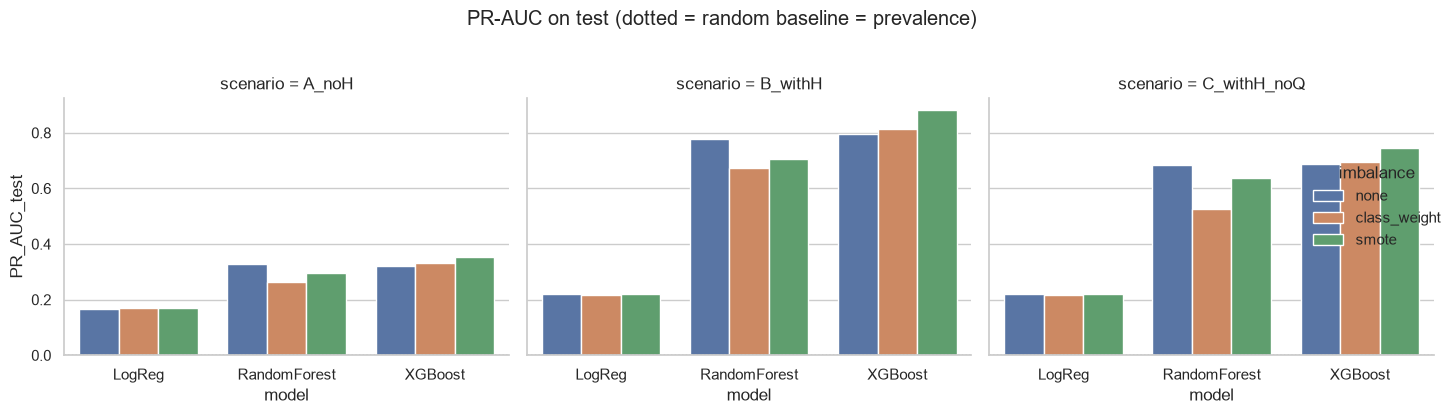

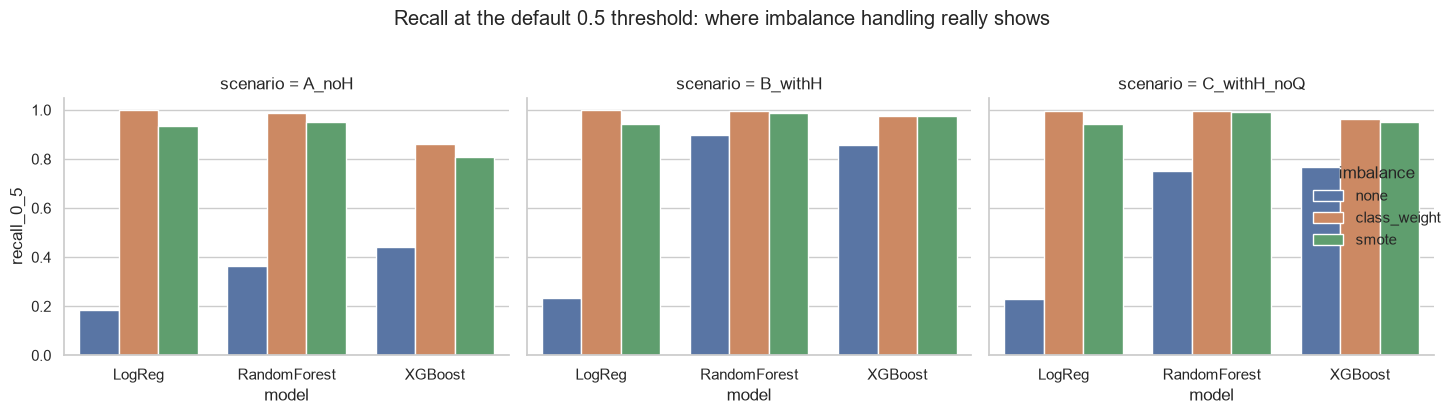

In [8]:
print("Mean over models/scenarios, by imbalance strategy (test):")
display(res.groupby("imbalance")[["PR_AUC_test", "precision_0_5", "recall_0_5", "f1_0_5", "f1_tuned"]].mean().round(4))

g = sns.catplot(data=res, x="model", y="PR_AUC_test", hue="imbalance", col="scenario", kind="bar", height=4, aspect=1.1)
for ax in g.axes.flat: ax.axhline(test.y_pha.mean(), color="k", ls=":", lw=1)
g.fig.suptitle("PR-AUC on test (dotted = random baseline = prevalence)", y=1.03)
savefig("04_pr_auc_grid")

g = sns.catplot(data=res, x="model", y="recall_0_5", hue="imbalance", col="scenario", kind="bar", height=4, aspect=1.1)
g.fig.suptitle("Recall at the default 0.5 threshold: where imbalance handling really shows", y=1.03)
savefig("04_recall_grid")

### 5.2 Scenarios: what does `H` and `q` buy?

In [9]:
best_each = res.loc[res.groupby("scenario")["PR_AUC_val"].idxmax(), show].round(4)
best_each

,scenario,model,imbalance,PR_AUC_val,PR_AUC_test,accuracy_test_0_5,accuracy_tuned,precision_0_5,recall_0_5,f1_0_5,precision_tuned,recall_tuned,f1_tuned
8,A_noH,XGBoost,smote,0.3810,0.3519,0.9934,0.9958,0.2245,0.8063,0.3513,0.2875,0.6077,0.3904
17,B_withH,XGBoost,smote,0.8491,0.8821,0.9982,0.9990,0.5528,0.9758,0.7058,0.7267,0.8886,0.7996
26,C_withH_noQ,XGBoost,smote,0.7063,0.7467,0.9970,0.9984,0.4203,0.9516,0.5831,0.5996,0.8087,0.6887


### 5.3 PR curves of the best model per scenario

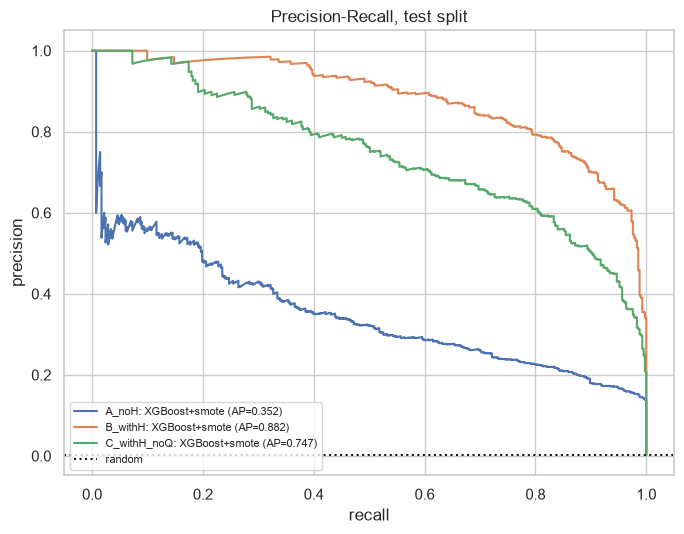

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for scen, (_, pipe, key, thr) in best_by_scen.items():
    p = test_proba[key]
    pr, rc, _ = precision_recall_curve(test["y_pha"], p)
    ax.plot(rc, pr, label=f"{scen}: {key[1]}+{key[2]} (AP={average_precision_score(test['y_pha'], p):.3f})")
ax.axhline(test.y_pha.mean(), color="k", ls=":", label="random"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision-Recall, test split"); ax.legend(fontsize=8)
savefig("04_pr_curves")

## 6. Operating points for the overall best model
Planetary defence is asymmetric: **a missed PHA costs far more than a false alarm.** So besides the F1-optimal threshold we also pick the threshold that keeps **recall ≥ 95% on validation**, then report what that costs in false alarms on test.

In [11]:
_, best_pipe, (b_scen, b_model, b_imb), thr_f1 = global_best
feats = SCENARIOS[b_scen]
pv = best_pipe.predict_proba(val[feats])[:, 1]; pt = best_pipe.predict_proba(test[feats])[:, 1]

pr, rc, th = precision_recall_curve(val["y_pha"], pv)
ok = np.where(rc[:-1] >= 0.95)[0]
thr_r95 = float(th[ok[-1]]) if len(ok) else float(th[0])

ops = {}
for name, t in [("default 0.5", 0.5), ("F1-optimal (val)", thr_f1), ("recall>=95% (val)", thr_r95)]:
    pred = (pt >= t).astype(int); tn, fp, fn, tp = confusion_matrix(test["y_pha"], pred).ravel()
    ops[name] = dict(threshold=t, TP=tp, FN=fn, FP=fp, precision=tp/max(tp+fp, 1), recall=tp/(tp+fn), f1=2*tp/(2*tp+fp+fn),
                     false_alarms_per_PHA_found=fp/max(tp, 1))
print(f"Best model: scenario={b_scen}, model={b_model}, imbalance={b_imb}")
pd.DataFrame(ops).T.round(4)

Best model: scenario=B_withH, model=XGBoost, imbalance=smote


,threshold,TP,FN,FP,precision,recall,f1,false_alarms_per_PHA_found
default 0.5,0.5000,403.0,10.0,326.0,0.5528,0.9758,0.7058,0.8089
F1-optimal (val),0.9212,367.0,46.0,138.0,0.7267,0.8886,0.7996,0.3760
recall>=95% (val),0.3946,406.0,7.0,363.0,0.5280,0.9831,0.6870,0.8941


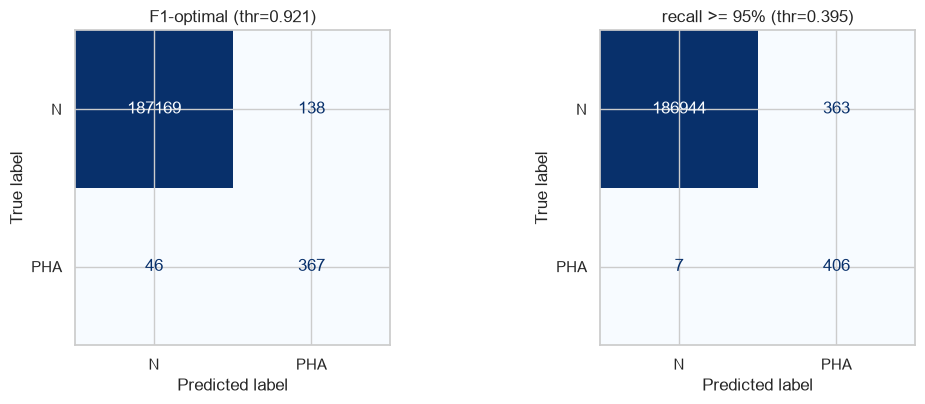

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, t) in zip(axes, [("F1-optimal", thr_f1), ("recall >= 95%", thr_r95)]):
    ConfusionMatrixDisplay.from_predictions(test["y_pha"], (pt >= t).astype(int), display_labels=["N", "PHA"],
                                            cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(f"{name} (thr={t:.3f})")
savefig("04_confusion_matrices")

## 7. Save the best model

In [13]:
bundle = {"pipeline": best_pipe, "features": feats, "scenario": b_scen, "model": b_model, "imbalance": b_imb,
          "thresholds": {"f1_optimal": thr_f1, "recall_95": thr_r95, "default": 0.5},
          "target": "y_pha (1 = Potentially Hazardous Asteroid)", "test_prevalence": float(test.y_pha.mean()),
          "split_seed": U.SEED}
joblib.dump(bundle, U.MODELS / "case1_pha_best.joblib")
print("saved", U.MODELS / "case1_pha_best.joblib")

saved C:\Projects\Planetary_Defense_Analytics\models\case1_pha_best.joblib
